# Scraping onto both global constraints: real-power and rotated ellipsoids

Variant of `scraping.ipynb` (same setup and scraping step, but GCD with 20 iterations instead of 100). There, the target $x_\mathrm{p}$ of each scraping step is the radial
projection onto the real-power ellipsoid, so the reactive power residual stays at $c_\mathrm{im}/r^2 \approx 6\cdot10^2$.

**Rotated ellipsoids.** The rotated real power $\operatorname{Re}[e^{j\theta} I^H(V - Z_\mathrm{tot} I)] = 0$ has the Hermitian matrix $\operatorname{Re}(e^{j\theta} Z_\mathrm{tot}) = \cos\theta R - \sin\theta X$. It is
positive definite on $\theta \in (-1.2\cdot10^{-4}°, 0.0278°)$ (`VscatBoundRotation.ipynb`), so it is again an ellipsoid on which every structure lies:
$$(I - I_\theta)^H H_\theta (I - I_\theta) = r_\theta^2, \qquad I_\theta = \tfrac12 H_\theta^{-1} e^{j\theta} V, \qquad r_\theta^2 = \tfrac14 V^H H_\theta^{-1} V .$$
Its distance $d_\theta$ contains $\tan\theta$ times the reactive residual. Two angles together are equivalent to both global constraints.

**Targets compared, all with respect to the original excitation $V$.**
1. **Radial**: the radial projection onto the real-power ellipsoid, as in `scraping.ipynb`.
2. **Both, $A_0$ metric**: the exact projection onto both global constraints, $\min (x - x_\phi)^H M (x - x_\phi)$ with $M = W^H R W$ (the real-power ellipsoid
   metric). It is a two-constraint QCQP solved by its dual.
3. **Both, rotated metric**: the same projection with $M = W^H H_{\theta_\mathrm{opt}} W$, the best-conditioned rotated ellipsoid.

Each step records $d_0$, $d_{\theta_\mathrm{opt}}$ and $c_\mathrm{im}/r^2$, the source change $e_j$, the dual value and the smallest Lagrangian eigenvalue. The final scraped currents
are then used for pointwise inference.

In [1]:
import numpy as np
import scipy.sparse as sp
import time
from dolphindes.cvxopt import DenseSharedProjQCQP, OptimizationHyperparameters
import copy
import matplotlib.pyplot as plt
from dolphindes.cvxopt.gcd import GCDHyperparameters

In [2]:
matrixSet = "patch21ka1"   # "dipole" | "patch21ka1": operators loaded from *_{matrixSet}.txt (both ka = 1)

# Physical constants
epsilon_0 = 8.854e-12 # F/m
mu_0 = 4e-7 * np.pi # H/m
c = 1/np.sqrt(epsilon_0 * mu_0) # speed of light in vacuum

E0 = 1e3 # plane wave amplitude in V/m

frequency = 2.45e9 # frequency in Hz
wavelength = c / frequency # wavelength in m
print(f"Wavelength: {wavelength} m")

ka = 1 # electrical size of the antenna
k = 2 * np.pi / wavelength # wavenumber
a = ka / k # antenna circumradius
print(f"Antenna circumradius: {a} m")

omega = 2 * np.pi * frequency # angular frequency

conductivity_reduction_factor = 1 # factor to reduce conductivity for testing purposes
copper_conductivity = conductivity_reduction_factor*5.96e7 # S/m
copper_permittivity = 1 + 1j * copper_conductivity / (omega * epsilon_0) # copper permittivity in dimensionless units
print(f"Copper permittivity: {copper_permittivity:.2e}")

Wavelength: 0.1223655664053944 m
Antenna circumradius: 0.019475084757658086 m
Copper permittivity: 1.00e+00+4.37e+08j


In [3]:
# Calculate surface impedance
delta = np.sqrt(2 / (omega * mu_0 * copper_conductivity)) # skin depth in m
Zs = (1 + 1j) / (copper_conductivity * delta)
print(f"Surface impedance: {Zs} Ω")

# Load matrices from text files
Lmat = np.loadtxt(f"Lmat_{matrixSet}.txt", delimiter=',') # lossy matrix

Ndes = Lmat.shape[0] # number of design variables
print(f"Matrix set: {matrixSet}, number of design variables: {Ndes}")

Lchol = np.linalg.cholesky(Lmat).conj().T
LcholInv = np.linalg.inv(Lchol)

def Msym(M):
    return(0.5*(M.conj().T + M))

def Mchol(M):
    return(Msym(LcholInv.conj().T @ M @ LcholInv))

R0 = np.loadtxt(f"R0_{matrixSet}.txt", delimiter=',') # radiated power matrix
R0 = Mchol(R0)

X0 = np.loadtxt(f"X0_{matrixSet}.txt", delimiter=',') # reactive power matrix
X0 = Mchol(X0)

Vinc = np.loadtxt(f"V_{matrixSet}.txt", delimiter=',') # voltage excitation vector
Vinc = E0*Vinc
def Vchol(v):
    return(LcholInv.conj().T @ v)
Vinc = Vchol(Vinc)

Zmat = Zs * np.eye(Ndes) # material impedance matrix
Z0 = R0 + 1j*X0 # free-space impedance matrix
Ztot = Z0 + Zmat # total impedance matrix

def evalObjI(Ivec):
    # radiated power in the current basis
    return(0.5*np.real(Ivec.conj().T @ R0 @ Ivec))

# full plate performance
Ifull = np.linalg.solve(Ztot, Vinc) # current distribution for full plate
Pfull = evalObjI(Ifull) # objective for full plate
print(f"Objective for full plate: {Pfull:.6e} W")

Surface impedance: (0.012739130327240646+0.012739130327240646j) Ω
Matrix set: patch21ka1, number of design variables: 233
Objective for full plate: 4.114174e-02 W


In [4]:
print(f"cond(Z0) = {np.linalg.cond(Z0):.3e}")
W = np.linalg.inv(Z0)   # Z0^{-1}
WH = W.conj().T

Obj = -0.5 * Msym(WH @ R0 @ W)
obj = np.zeros(Ndes, dtype=complex)
obj0 = 0.0

def VtoI(Vsca):
    return(-W @ Vsca)

def evalObj(Vsca):
    return(-np.real(Vsca.conj().T @ Obj @ Vsca) + 2*np.real(Vsca.conj().T @ obj) + obj0)

Vfull = -Z0 @ Ifull # scattered voltage for full plate
print(f"Objective for full plate in Vsca: {evalObj(Vfull):.6e} W (I basis {Pfull:.6e} W)")

cond(Z0) = 1.174e+03
Objective for full plate in Vsca: 4.114174e-02 W (I basis 4.114174e-02 W)


In [5]:
A1 = np.eye(Ndes) + np.conj(Zs) * WH
A2 = W
s1 = -0.5 * Vinc

qList = [1, -1j]   # real and imaginary part (real and reactive power), p = q 1
Plist = [sp.diags(np.conj(q)*np.ones(Ndes, dtype=complex)) for q in qList]   # P' = diag(p^*)

def projRes(x, Pp):
    # Re(-x^H A1 P' A2 x + 2 x^H A2^H P'^H s1)
    return(np.real(-x.conj() @ A1 @ (Pp @ (A2 @ x)) + 2*x.conj() @ (A2.conj().T @ (Pp.conj().T @ s1))))

def directRes(Vsca, p):
    # Re[I^H diag(p) (V + Vsca - Zs I)] evaluated directly
    I = VtoI(Vsca)
    return(np.real(np.sum(p*np.conj(I)*(Vinc + Vsca - Zs*I))))

print("power conservation residuals at full plate:",
      [f"{projRes(Vfull, Pp):.2e} (direct {directRes(Vfull, q*np.ones(Ndes)):.2e})" for Pp, q in zip(Plist, qList)])

# check: shared projector form equals the direct constraint for a random projector at a random point
pRand = np.random.randn(Ndes) + 1j*np.random.randn(Ndes)
xRand = np.random.randn(Ndes) + 1j*np.random.randn(Ndes)
print(f"random p, random x: shared form {projRes(xRand, sp.diags(np.conj(pRand))):.6e}, direct {directRes(xRand, pRand):.6e}")

power conservation residuals at full plate: ['-1.39e-17 (direct -2.89e-17)', '4.44e-16 (direct -4.76e-16)']
random p, random x: shared form 5.999238e-01, direct 5.999238e-01


In [6]:
QCQP = DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, Plist, A2=A2, verbose=1)

lags_init = np.array([1.0, 0.0])   # lambda = 1 on the real power constraint
print(f"initial lags dual feasible: {QCQP.is_dual_feasible(lags_init)}")

opt_params = OptimizationHyperparameters(opttol=1e-6,
    gradConverge=True,
    min_inner_iter=10,
    max_restart=10,
    penalty_ratio=1e-2,
    penalty_reduction=0.1,
    break_iter_period=5,
    verbose=0)

t1 = time.time()
result = QCQP.solve_current_dual_problem(method='newton', init_lags=lags_init, opt_params=opt_params)
print(f"bound: {result[0]:.6e} W, time: {time.time()-t1:.2f}s, Lagrange multipliers: {QCQP.current_lags}")

Precomputed 2 A matrices and Fs vectors.
initial lags dual feasible: True
bound: 1.847944e+01 W, time: 0.11s, Lagrange multipliers: [ 8.83797881e-01 -4.10993941e-05]


## GCD

20 GCD iterations (fewer than the 100 of `scraping.ipynb`). Set `cacheFile` to a path to store and reuse the GCD state
(projectors and multipliers); GCD contains randomness, so a fresh run differs by about $10^{-3}$ in $d$.

In [7]:
Ngcd = 20
cacheFile = None   # e.g. "scraping_gcd100.npz"

import os
if cacheFile is not None and os.path.exists(cacheFile):
    st = np.load(cacheFile)
    PlistG = [sp.diags(st['Pdata'][:, k]) for k in range(st['Pdata'].shape[1])]
    gQCQP = DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, PlistG, A2=A2, verbose=0)
    gQCQP.current_lags = st['lags']
    gQCQP.current_dual = gQCQP.get_dual(gQCQP.current_lags)[0]
    gQCQP.current_xstar = gQCQP._get_xstar(gQCQP.current_lags)[0]
else:
    gQCQP = copy.deepcopy(QCQP)
    gQCQP.verbose = 0
    t1 = time.time()
    gQCQP.run_gcd(GCDHyperparameters(max_proj_cstrt_num=2 + 2*Ngcd, max_gcd_iter_num=Ngcd,
                                     gcd_iter_period=Ngcd + 1, opt_params=opt_params))
    print(f"GCD time {time.time()-t1:.1f}s")
    if cacheFile is not None:
        np.savez(cacheFile, Pdata=gQCQP.Proj.get_Pdata_column_stack(), lags=gQCQP.current_lags)
gcdLags = gQCQP.current_lags.copy()
print(f"GCD bound {gQCQP.current_dual:.6e} W, {gQCQP.n_proj_constr} projectors")

At GCD iteration #1, best dual bound found is             18.479439958269765.
min eigenvalue: 6.851365e-09
At GCD iteration #2, best dual bound found is             18.331563359435297.
min eigenvalue: 5.900530e-09


At GCD iteration #3, best dual bound found is             18.219582846471106.
min eigenvalue: 3.891568e-09
At GCD iteration #4, best dual bound found is             18.116345286639007.
min eigenvalue: 1.260090e-09


At GCD iteration #5, best dual bound found is             18.05814191322036.
min eigenvalue: 3.000881e-10


At GCD iteration #6, best dual bound found is             18.014874486872746.
min eigenvalue: 4.902872e-11


At GCD iteration #7, best dual bound found is             17.996930231780155.
min eigenvalue: 3.607544e-10


...

At GCD iteration #17, best dual bound found is             17.83804120550325.
min eigenvalue: 8.261564e-15


At GCD iteration #18, best dual bound found is             17.819930222226294.
min eigenvalue: 9.791118e-15


At GCD iteration #19, best dual bound found is             17.802055912915687.
min eigenvalue: 8.766385e-15


At GCD iteration #20, best dual bound found is             17.78978539947702.
min eigenvalue: 6.428015e-15


At GCD iteration #21, best dual bound found is             17.778714111632695.
GCD time 26.9s
GCD bound 1.777871e+01 W, 42 projectors


## Ellipsoids, distances and the projection onto both global constraints

In [8]:
import scipy.linalg as sla

Rtot = Msym(Ztot)
Xtot = (Ztot - Ztot.conj().T) / 2j
Xtot = Msym(Xtot)
g = sla.eigh(Xtot.real, Rtot.real, eigvals_only=True)
thHi = np.arctan(1/g.max())
thScan = np.linspace(0, thHi, 400)[1:-1]
condV = [np.linalg.cond(Msym(W.conj().T @ (np.cos(t)*Rtot - np.sin(t)*Xtot) @ W)) for t in thScan]
thOpt = thScan[int(np.argmin(condV))]
print(f"rotated real power positive definite up to {np.degrees(thHi):.4e} deg; best-conditioned angle {np.degrees(thOpt):.4e} deg, "
      f"cond W^H H W {min(condV):.2e} (theta = 0: {np.linalg.cond(Msym(W.conj().T @ Rtot @ W)):.2e})")

def Hth(th):
    return np.cos(th)*Rtot - np.sin(th)*Xtot

Cth = {th: np.linalg.cholesky(Hth(th)).conj().T for th in [0.0, thOpt]}

def ellipsoid(V, th=0.0):
    H = Hth(th)
    Ic = 0.5 * np.linalg.solve(H, np.exp(1j*th)*V)
    r = 0.5 * np.sqrt(np.real(V.conj() @ np.linalg.solve(H, V)))
    return Ic, r

def measures(x, V):
    # signed relative distances from the real-power and the rotated ellipsoid of V, normalized reactive residual
    I = VtoI(x)
    out = []
    for th in [0.0, thOpt]:
        Ic, r = ellipsoid(V, th)
        out.append((np.linalg.norm(Cth[th] @ (I - Ic)) - r) / r)
    Ic, r = ellipsoid(V)
    cim = np.real(I.conj() @ Xtot @ I + I.conj() @ (1j * V)) / r**2
    return out[0], out[1], cim

# check: a structure (the full plate) lies on every ellipsoid
print("full plate: d_0 {:+.1e}, d_theta {:+.1e}, c_im/r^2 {:+.1e}".format(*measures(Vfull, Vinc)))

def projectRadial(x, V):
    I = VtoI(x)
    Ic, r = ellipsoid(V)
    Ip = Ic + r / np.linalg.norm(Cth[0.0] @ (I - Ic)) * (I - Ic)
    return -Z0 @ Ip

metricBoth = {"both, A0 metric": Msym(WH @ Rtot @ W), "both, rotated metric": Msym(WH @ Hth(thOpt) @ W)}

def projectBoth(x0, V, M):
    # argmin (x - x0)^H M (x - x0) s.t. the global real and reactive power of V (two-constraint QCQP, solved by its dual)
    M = M/np.linalg.norm(M, 2)
    Qp = DenseSharedProjQCQP(M, M @ x0, -np.real(x0.conj() @ M @ x0), A1, -0.5*V, Plist, A2=A2, verbose=0)
    Qp.solve_current_dual_problem(method='newton', init_lags=np.zeros(2), opt_params=opt_params)
    return Qp.current_xstar

for name, x in [("full plate", Vfull), ("global constraints", QCQP.current_xstar), (f"GCD {Ngcd}", gQCQP.current_xstar)]:
    print(f"{name:20s} d_0 {measures(x, Vinc)[0]:+.3e}, d_theta {measures(x, Vinc)[1]:+.3e}, c_im/r^2 {measures(x, Vinc)[2]:+.3e}")
for name, M in metricBoth.items():
    xp = projectBoth(gQCQP.current_xstar, Vinc, M)
    print(f"GCD current projected ({name}): d_0 {measures(xp, Vinc)[0]:+.1e}, d_theta {measures(xp, Vinc)[1]:+.1e}, c_im/r^2 {measures(xp, Vinc)[2]:+.1e}, "
          f"move {np.linalg.norm(xp - gQCQP.current_xstar)/np.linalg.norm(gQCQP.current_xstar):.2e}")

rotated real power positive definite up to 2.7803e-02 deg; best-conditioned angle 2.7664e-02 deg, cond W^H H W 4.91e+04 (theta = 0: 1.17e+07)
full plate: d_0 -2.6e-16, d_theta -2.4e-15, c_im/r^2 -1.9e-16
full plate           d_0 -2.620e-16, d_theta -2.418e-15, c_im/r^2 -1.932e-16
global constraints   d_0 +5.884e-09, d_theta +1.635e-08, c_im/r^2 -6.329e-05
GCD 20               d_0 -1.987e-03, d_theta -1.054e-01, c_im/r^2 +5.270e+02
GCD current projected (both, A0 metric): d_0 -1.3e-08, d_theta -8.7e-07, c_im/r^2 +4.6e-03, move 1.26e+00


GCD current projected (both, rotated metric): d_0 +2.3e-08, d_theta +1.2e-08, c_im/r^2 +2.8e-05, move 3.35e-01


## Scraping loop

As in `scraping.ipynb`, $\delta s_j = A_{\phi j}(x_{\mathrm{p},j} - x_{\phi j})$ and $V_{j+1} = V_j + \eta_j S(\lambda_j)^{-1}\delta s_j$, accepted when the dual follows its first-order
prediction within $\tau |D_j|$. Only the target $x_{\mathrm{p},j}$ changes: radial, or the exact projection onto both global constraints of the original $V$.

In [9]:
def scrape(target, J=8, tau=1e-2):
    Q = copy.deepcopy(gQCQP)
    Q.s1 = -0.5 * Vinc
    Q.compute_precomputed_values()
    Q.solve_current_dual_problem('newton', init_lags=gcdLags.copy(), opt_params=opt_params)
    lags, x, V, D = Q.current_lags.copy(), Q.current_xstar.copy(), Vinc.copy(), Q.current_dual
    q = lambda lg: Q.Proj.Pdiags.conj() @ lg[:Q.n_proj_constr]
    hist = []
    def record(j, eta, lin):
        d0, dth, cim = measures(x, Vinc)
        A = Msym(Q._get_total_A(lags))
        hist.append(dict(j=j, eta=eta, D=D, lin=lin, d=d0, dth=dth, cim=cim, e=np.linalg.norm(V - Vinc)/np.linalg.norm(Vinc),
                         mineig=np.linalg.eigvalsh(A)[0]/np.linalg.eigvalsh(A)[-1], x=x.copy()))
    record(0, 0.0, D)
    for j in range(1, J + 1):
        A = Q._get_total_A(lags)
        xp = projectRadial(x, Vinc) if target == "radial" else projectBoth(x, Vinc, metricBoth[target])
        ds = A @ (xp - x)
        dV = -2 * (Z0.conj().T @ ds) / q(lags)
        eta = 1.0
        while True:
            Vn = V + eta * dV
            Q.s1 = -0.5 * Vn
            Q.compute_precomputed_values()
            lin = D + 2 * eta * np.real(x.conj() @ ds)
            Q.solve_current_dual_problem('newton', init_lags=lags, opt_params=opt_params)
            if abs(Q.current_dual - lin) <= tau * abs(D) or eta < 1e-3:
                break
            eta /= 2
        lags, x, V, D = Q.current_lags.copy(), Q.current_xstar.copy(), Vn, Q.current_dual
        record(j, eta, lin)
    return hist

def show(hist, title):
    print(title)
    print(f"{'j':>2} {'eta':>5} {'D_j (W)':>12} {'lin (W)':>12} {'d_0':>10} {'d_theta':>10} {'cim/r2':>10} {'e_j':>9} {'min/max eig':>11}")
    for h in hist:
        print(f"{h['j']:2d} {h['eta']:5.2f} {h['D']:12.6e} {h['lin']:12.6e} {h['d']:+10.3e} {h['dth']:+10.3e} {h['cim']:+10.3e} {h['e']:9.2e} {h['mineig']:11.2e}")

hists = {}
for target in ["radial", "both, A0 metric", "both, rotated metric"]:
    t1 = time.time()
    hists[target] = scrape(target)
    show(hists[target], f"\ntarget: {target} ({time.time() - t1:.0f}s)")


target: radial (23s)
 j   eta      D_j (W)      lin (W)        d_0    d_theta     cim/r2       e_j min/max eig
 0  0.00 1.777871e+01 1.777871e+01 -1.957e-03 -1.049e-01 +5.248e+02  0.00e+00    3.74e-12
 1  1.00 1.780864e+01 1.780861e+01 -4.429e-04 -1.039e-01 +5.263e+02  1.09e-03    3.82e-12
 2  1.00 1.781543e+01 1.781542e+01 -1.438e-04 -1.039e-01 +5.275e+02  1.34e-03    3.28e-11
 3  1.00 1.781763e+01 1.781763e+01 -2.373e-05 -1.037e-01 +5.270e+02  1.42e-03    4.07e-12
 4  1.00 1.781800e+01 1.781799e+01 -1.503e-05 -1.038e-01 +5.276e+02  1.43e-03    3.35e-11
 5  1.00 1.781822e+01 1.781823e+01 +7.000e-05 -1.034e-01 +5.263e+02  1.44e-03    4.11e-12
 6  1.00 1.781715e+01 1.781715e+01 -1.812e-05 -1.035e-01 +5.263e+02  1.40e-03    3.78e-12
 7  1.00 1.781743e+01 1.781743e+01 +3.425e-05 -1.035e-01 +5.264e+02  1.41e-03    4.17e-12
 8  1.00 1.781690e+01 1.781690e+01 -2.770e-05 -1.037e-01 +5.272e+02  1.39e-03    4.00e-12



target: both, A0 metric (20s)
 j   eta      D_j (W)      lin (W)        d_0    d_theta     cim/r2       e_j min/max eig
 0  0.00 1.777871e+01 1.777871e+01 -1.941e-03 -1.049e-01 +5.249e+02  0.00e+00    3.82e-12
 1  1.00 1.786016e+01 1.780934e+01 +5.245e-03 -4.658e-02 +2.658e+02  1.13e-02    8.45e-12
 2  1.00 1.783858e+01 1.782977e+01 +6.974e-03 -1.137e-02 +8.960e+01  1.62e-02    2.47e-11
 3  1.00 1.775502e+01 1.775402e+01 +3.811e-03 -3.372e-03 +3.387e+01  1.84e-02    5.18e-10
 4  1.00 1.770645e+01 1.770627e+01 +1.837e-03 -5.543e-04 +1.059e+01  1.97e-02    8.92e-10
 5  1.00 1.768173e+01 1.768170e+01 +7.260e-04 -4.033e-04 +5.170e+00  2.03e-02    1.69e-09
 6  1.00 1.767225e+01 1.767224e+01 +3.104e-04 -3.578e-04 +3.204e+00  2.05e-02    2.80e-09
 7  1.00 1.766846e+01 1.766846e+01 +1.780e-04 +1.410e-04 -1.867e-02  2.06e-02    1.62e-09
 8  1.00 1.766580e+01 1.766580e+01 +4.633e-05 +3.233e-05 +1.854e-02  2.07e-02    1.44e-09



target: both, rotated metric (26s)
 j   eta      D_j (W)      lin (W)        d_0    d_theta     cim/r2       e_j min/max eig
 0  0.00 1.777871e+01 1.777871e+01 -1.936e-03 -1.049e-01 +5.251e+02  0.00e+00    3.84e-12
 1  0.50 1.723880e+01 1.714631e+01 -2.384e-02 -8.688e-02 +3.481e+02  1.76e-02    3.61e-11
 2  0.50 1.704742e+01 1.700052e+01 -2.389e-02 -5.946e-02 +2.116e+02  3.42e-02    5.85e-11
 3  1.00 1.700443e+01 1.692864e+01 -6.859e-03 -1.134e-02 +3.217e+01  5.82e-02    5.71e-10
 4  1.00 1.704933e+01 1.704711e+01 -6.390e-04 -1.728e-03 +6.614e+00  6.34e-02    1.83e-09
 5  1.00 1.704525e+01 1.704519e+01 -1.346e-04 -4.445e-04 +1.826e+00  6.40e-02    3.45e-09
 6  1.00 1.704340e+01 1.704339e+01 -2.804e-05 -2.132e-05 -1.843e-03  6.41e-02    2.61e-09
 7  1.00 1.704388e+01 1.704388e+01 +7.003e-07 +9.951e-07 -2.435e-03  6.41e-02    2.61e-09
 8  1.00 1.704388e+01 1.704388e+01 +9.456e-08 +5.829e-07 -2.734e-03  6.41e-02    2.60e-09


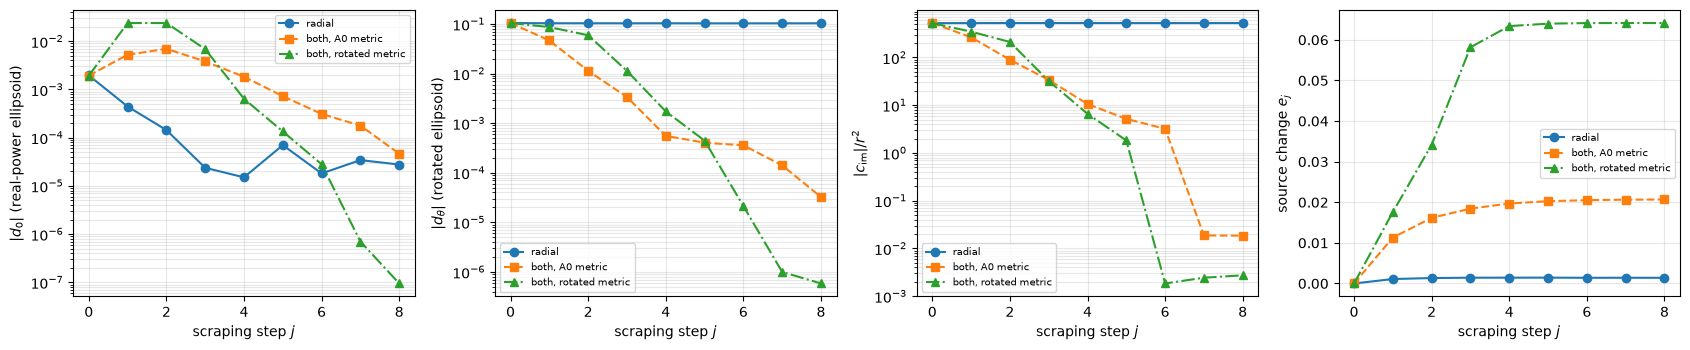

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for (target, hist), m in zip(hists.items(), ['o-', 's--', '^-.']):
    j = [h['j'] for h in hist]
    axes[0].semilogy(j, [abs(h['d']) for h in hist], m, label=target)
    axes[1].semilogy(j, [abs(h['dth']) for h in hist], m, label=target)
    axes[2].semilogy(j, [abs(h['cim']) for h in hist], m, label=target)
    axes[3].plot(j, [h['e'] for h in hist], m, label=target)
for ax, lab in zip(axes, [r'$|d_0|$ (real-power ellipsoid)', r'$|d_\theta|$ (rotated ellipsoid)', r'$|c_\mathrm{im}|/r^2$', r'source change $e_j$']):
    ax.set_xlabel('scraping step $j$'); ax.set_ylabel(lab); ax.grid(True, which='both', alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## Inference from the scraped currents

Pointwise inference (current fit and voltage fit, as in `VscatBound.ipynb`) of the unscraped GCD current and of the last scraped current of every
target, evaluated by the realized scattered power (relaxed, and the best binary structure over the thresholds $0.05, \dots, 0.95$).

In [11]:
from scipy.optimize import lsq_linear

def fitDensity(Vsca):
    b = (Vinc + Vsca)/Zs
    I = VtoI(Vsca)
    return np.clip(np.real(np.conj(b)*I)/np.abs(b)**2, 0, 1)

def fitDensityVoltage(Vsca):
    Vtot = Vinc + Vsca
    M = Z0 * Vtot[None, :]
    r = -Zs * Vsca
    return lsq_linear(np.vstack([M.real, M.imag]), np.concatenate([r.real, r.imag]), bounds=(0, 1), method='bvls', tol=1e-12).x

def realizedObj(rho):
    S = np.diag(rho.astype(complex))
    return evalObjI(np.linalg.solve(Zs*np.eye(Ndes) + S @ Z0, S @ Vinc))

thsBin = np.linspace(0.05, 0.95, 19)
D0 = gQCQP.current_dual
cases = {"GCD x* (j = 0)": hists["radial"][0]["x"], **{f"scraped, {t} (j = {h[-1]['j']})": h[-1]["x"] for t, h in hists.items()}}
for name, x in cases.items():
    rhoC = Zs*VtoI(x)/(Vinc + x)
    parts = []
    for fname, fit in [("current fit", fitDensity), ("voltage fit", fitDensityVoltage)]:
        rho = fit(x)
        parts.append(f"{fname}: relaxed P/D {realizedObj(rho)/D0:.4f}, best binary {max(realizedObj((rho > t).astype(float)) for t in thsBin)/D0:.4f}")
    print(f"{name:42s}: max|complex density| {np.abs(rhoC).max():.1e}; " + "; ".join(parts), flush=True)

GCD x* (j = 0)                            : max|complex density| 1.6e-02; current fit: relaxed P/D 0.0000, best binary 0.0000; voltage fit: relaxed P/D 0.0000, best binary 0.0000


scraped, radial (j = 8)                   : max|complex density| 1.2e-02; current fit: relaxed P/D 0.0000, best binary 0.0000; voltage fit: relaxed P/D 0.0000, best binary 0.0000


scraped, both, A0 metric (j = 8)          : max|complex density| 2.0e-03; current fit: relaxed P/D 0.0000, best binary 0.0000; voltage fit: relaxed P/D 0.0000, best binary 0.0000


scraped, both, rotated metric (j = 8)     : max|complex density| 1.5e-02; current fit: relaxed P/D 0.0000, best binary 0.0000; voltage fit: relaxed P/D 0.0000, best binary 0.0000


## Conclusions (20 and 100 GCD iterations, `scrapingBothEllipsoids20.ipynb` and `scrapingBothEllipsoids.ipynb`)

These are one run each; GCD is not exactly reproducible. $D_j$ is the dual value of the perturbed problem (excitation $V_j$), a bound for $V_j$, not for $V$.
$d_0$, $d_\theta$ and $c_\mathrm{im}/r^2$ are measured with respect to the original excitation $V$.

**Starting point.** The GCD dual current lies just inside the real-power ellipsoid but far inside the rotated one, and violates the reactive power.

| GCD iterations | $D_0$ | $d_0$ | $d_\theta$ | $c_\mathrm{im}/r^2$ | min/max eig |
|---|---|---|---|---|---|
| 20 | 17.779 W | $-2.0\times10^{-3}$ | $-0.105$ | 525 | $4\times10^{-12}$ |
| 100 | 17.545 W | $-5.3\times10^{-3}$ | $-0.117$ | 569 | $3\times10^{-12}$ |

**After 8 scraping steps.**

| target | GCD | $d_0$ | $d_\theta$ | $c_\mathrm{im}/r^2$ | $e_j$ | $D_8$ | min/max eig |
|---|---|---|---|---|---|---|---|
| radial (real power only) | 20 | $3\times10^{-5}$ | $-0.104$ | 527 | 0.14 % | 17.817 W | $4\times10^{-12}$ |
| both, $A_0$ metric | 20 | $5\times10^{-5}$ | $3\times10^{-5}$ | **0.019** | 2.1 % | 17.666 W | $1.4\times10^{-9}$ |
| both, rotated metric | 20 | $1\times10^{-7}$ | $6\times10^{-7}$ | **0.003** | 6.4 % | 17.044 W | $2.6\times10^{-9}$ |
| radial (real power only) | 100 | $2\times10^{-5}$ | $-0.111$ | 562 | 0.38 % | 17.648 W | $2\times10^{-12}$ |
| both, $A_0$ metric | 100 | $1.1\times10^{-2}$ | $-0.017$ | 138 | 8.0 % | 17.621 W | $1.8\times10^{-11}$ |
| both, rotated metric | 100 | $-2.2\times10^{-3}$ | $-0.008$ | 33 | 9.6 % | 15.991 W | $6\times10^{-11}$ |

1. **Radial scraping** reaches the real-power ellipsoid within 3 steps ($d_0 \sim 10^{-5}$) at a source change of 0.1–0.4 %, as in `scraping.ipynb`. The
   rotated distance and the reactive residual are untouched, and the Lagrangian stays as singular as GCD left it.
2. **Scraping onto both global constraints works with 20 GCD iterations.**
   - **Convergence.** Both ellipsoids are reached in 6–7 steps, and the reactive residual falls by 4–5 orders, from 525 to $10^{-2}$–$10^{-3}\,r^2$.
   - **Price.** A larger source change: 2.1 % with the $A_0$ metric, 6.4 % with the rotated metric (with two half steps at the start). The dual value
     falls by 0.6 % and 4 %.
   - **Side effect: a less singular dual.** The smallest Lagrangian eigenvalue rises 400–700-fold, to about $2\times10^{-9}$. Steering the dual current onto
     both constraints moves the perturbed dual partly away from the PSD boundary, which the radial target never does.
   - **Metric.** The $A_0$ metric needs a three times smaller source change; the rotated metric reaches the constraints more exactly.
3. **With 100 GCD iterations it does not converge in 8 steps.**
   - **Partial progress.** The reactive residual falls only 4–17-fold (to 138 and 33), $d_0$ even grows to $10^{-2}$ with the $A_0$ metric, and the source keeps
     drifting (8–10 % after 8 steps, still growing by about 0.8 % per step).
   - **Dual value.** It falls by up to 9 %.
   - **Why.** The 202 local projectors constrain how far the dual current can move for a given source change, so reaching both global constraints
     needs a much larger perturbation. The perturbed problem then moves away from the original one.
4. **Inference does not benefit.** For every scraped current, the current and voltage fits give structures with $P/D \leq 10^{-4}$, relaxed and binary, and the
   complex density stays at $|\rho| \leq 2\times10^{-2}$. Satisfying the two global constraints does not make the current locally structure-like.

**Assessment.**
- **For scraping:** yes, it helps. The two-ellipsoid target (exact two-constraint projection, $A_0$ or rotated metric) is the step that brings the dual
  current onto both global constraints, and it partially regularizes the perturbed dual.
- **The trade-off:** source change. It is acceptable after a short GCD (20 iterations: 2–6 %) but large after a long one (100 iterations: $> 8$ %, not
  converged).
- **The rotated ellipsoid's role:** a sharper progress measure ($d_\theta$) and a better-conditioned projection metric. It does not change the duals.
- **For pointwise inference:** no.

## Chained density fit on Narval (`scrapingBoth.py`, job 5871912, outputs in `results/scrapingBoth/`)

Four array tasks: 20 and 100 GCD iterations, two seeds each. The 100-iteration seed-0 task hit the 16 h limit during the last target, so 3 of
its 9 rotated-metric configurations are missing.

**Scraping (8 steps, original $V$).** The tasks reproduce the notebooks.
- **20 GCD iterations.** Scraping onto both constraints reduces $c_\mathrm{im}/r^2$ from about 510 to 1–3 ($A_0$ metric) and to $3\times10^{-4}$–1.1 (rotated metric),
  with source changes of 2.3–2.5 % and 6.7–6.9 % and the smallest Lagrangian eigenvalue at about $2\times10^{-9}$.
- **100 GCD iterations.** It does not converge: $c_\mathrm{im}/r^2$ stays at 28–133 after 8 steps, the source change at 7–10 %.
- **Radial.** $c_\mathrm{im}/r^2$ stays at 500–590 throughout.

**Chained fit.** For every target, the fit is run chained, from the first ($j = 0$) and from the last ($j = J$) Lagrangian, for $\mu = 0.1, 1, 10$ and 10
starts each. The scattered power of the best binary structure is in W; the dual bound is $D_0 = 17.78$ W (20 iterations) or 17.54 W (100), and
the lossless resonant dipole is 9.49 W.

| GCD | target | median over starts (median over configurations) | best of 10 starts (median over configurations) | best overall |
|---|---|---|---|---|
| 20 | radial | 0.11 | 7.4 | 9.51 |
| 20 | both, $A_0$ metric | 0.12 | 7.4 | **9.78** |
| 20 | both, rotated metric | 0.11 | 7.7 | 9.31 |
| 100 | radial | 0.12 | 7.1 | 9.49 |
| 100 | both, $A_0$ metric | 0.11 | 6.6 | 9.37 |
| 100 | both, rotated metric | 0.17 | 6.8 | 8.84 |

- **Some starts give good structures.** The best of 10 starts typically reaches 6.6–8 W (37–45 % of the bound), and the best overall 8.8–9.8 W
  (55 %, about the resonant dipole). The median start gives about 0.1 W: the fit is dominated by the random start.
- **No systematic gain.** There is none from the two-ellipsoid target, from chaining versus a single Lagrangian ($j = 0$ or $j = J$), from $\mu$, or
  from more GCD iterations. All differences are within the spread over seeds and starts. The single best structure (9.78 W) came from the
  chained fit after scraping onto both constraints ($A_0$ metric, $\mu = 1$, 20 GCD iterations). It is a single draw.

**Assessment.** Scraping onto both global constraints makes the dual current physically consistent with both power balances and partly
regularizes the dual (after a short GCD). It does not carry over to the inferred structures: the chained density fit performs the same for all
three targets, and its outcome is set by the starting density rather than by the scraped dual currents.